# Sales Forecasting Using Time-Series Analysis

**Project Goal:** Predict future sales using historical sales data.

### Techniques used
- Time-series preprocessing and aggregation
- Trend and seasonal analysis
- Promotion analysis
- Holiday analysis
- **SARIMAX (seasonal ARIMA with exogenous variables)**
- MAE and RMSE evaluation
- Actual vs forecast visualization
- Future sales forecasting

**Dataset:** Store Sales - Time Series Forecasting (Kaggle-style dataset)


## 1. Import Libraries

In [1]:
import os
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
# Find the working directory and dataset files
base_dir = Path.cwd()

zip_candidates = list(base_dir.glob("*.zip"))
required_files = ["train.csv", "test.csv", "holidays_events.csv"]

# Extract the first matching Store Sales ZIP if CSV files are not already available
if not all((base_dir / f).exists() for f in required_files):
    matching_zip = None
    for z in zip_candidates:
        if "store-sales" in z.name.lower() or "sales" in z.name.lower():
            matching_zip = z
            break

    if matching_zip is not None:
        with zipfile.ZipFile(matching_zip, "r") as z:
            z.extractall(base_dir)
        print(f"Extracted: {matching_zip.name}")
    else:
        print("No ZIP file found. Make sure train.csv, test.csv and holidays_events.csv are in the notebook folder.")

print("Working directory:", base_dir)
for f in required_files:
    print(f, "->", (base_dir / f).exists())


Working directory: C:\Users\geeta\Customer_Churn_prediction_Project
train.csv -> True
test.csv -> True
holidays_events.csv -> True


## 3. Load the Data

In [3]:
train = pd.read_csv(base_dir / "train.csv")
test = pd.read_csv(base_dir / "test.csv")
holidays = pd.read_csv(base_dir / "holidays_events.csv")

print("Train shape:", train.shape)
print("Test shape :", test.shape)
print("Holidays shape:", holidays.shape)

display(train.head())


Train shape: (3000888, 6)
Test shape : (28512, 5)
Holidays shape: (350, 6)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


## 4. Basic Data Understanding

In [4]:
print("Train columns:")
print(train.columns.tolist())

print("\nData types:")
print(train.dtypes)

print("\nMissing values:")
display(train.isnull().sum().to_frame("missing_values"))

print("\nDuplicate rows:", train.duplicated().sum())


Train columns:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']

Data types:
id               int64
date            object
store_nbr        int64
family          object
sales          float64
onpromotion      int64
dtype: object

Missing values:


,missing_values
id,0
date,0
store_nbr,0
family,0
sales,0
onpromotion,0



Duplicate rows: 0


## 5. Date Preprocessing

In [5]:
train["date"] = pd.to_datetime(train["date"])
test["date"] = pd.to_datetime(test["date"])
holidays["date"] = pd.to_datetime(holidays["date"])

print("Training period:", train["date"].min().date(), "to", train["date"].max().date())
print("Testing period :", test["date"].min().date(), "to", test["date"].max().date())


Training period: 2013-01-01 to 2017-08-15
Testing period : 2017-08-16 to 2017-08-31


In [6]:
daily_sales = (
    train.groupby("date", as_index=False)
         .agg(
             sales=("sales", "sum"),
             promotion=("onpromotion", "sum")
         )
)

daily_sales = daily_sales.sort_values("date")

# Create a complete daily index
all_train_dates = pd.date_range(
    daily_sales["date"].min(),
    daily_sales["date"].max(),
    freq="D"
)

daily_sales = (
    daily_sales.set_index("date")
               .reindex(all_train_dates)
               .rename_axis("date")
               .reset_index()
)

daily_sales["sales"] = daily_sales["sales"].fillna(0)
daily_sales["promotion"] = daily_sales["promotion"].fillna(0)

print("Daily observations:", len(daily_sales))
display(daily_sales.head())


Daily observations: 1688


,date,sales,promotion
0,2013-01-01,2511.618999,0.0
1,2013-01-02,496092.417944,0.0
2,2013-01-03,361461.231124,0.0
3,2013-01-04,354459.677093,0.0
4,2013-01-05,477350.121229,0.0


## 7. Daily Sales Trend

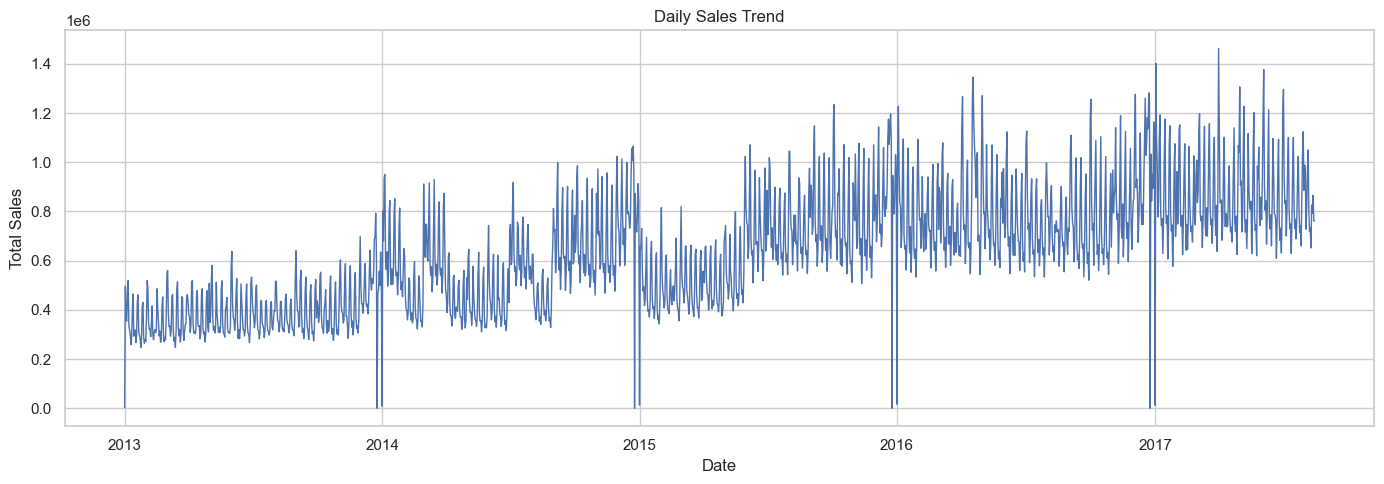

In [7]:
plt.figure(figsize=(14, 5))
plt.plot(daily_sales["date"], daily_sales["sales"], linewidth=1)
plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()


## 8. Monthly Sales Trend

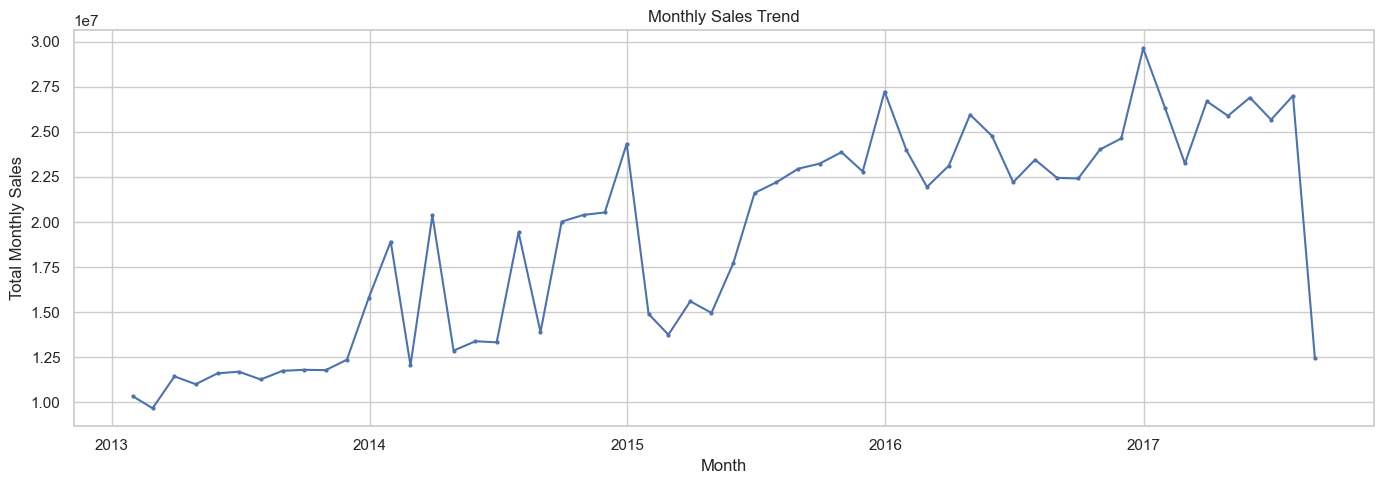

In [8]:
monthly_sales = (
    daily_sales.set_index("date")["sales"]
               .resample("ME")
               .sum()
)

plt.figure(figsize=(14, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o", markersize=2)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Monthly Sales")
plt.tight_layout()
plt.show()


## 9. Monthly Seasonality

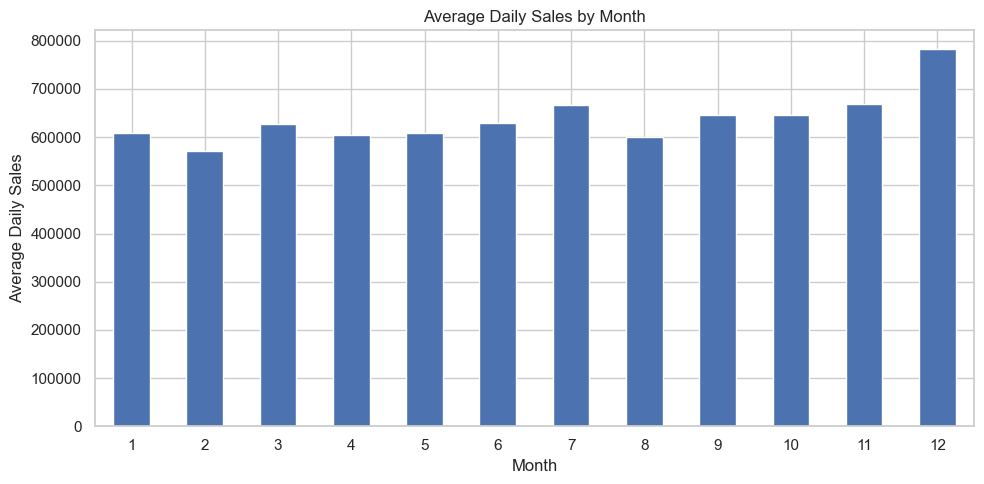

In [9]:
daily_sales["month"] = daily_sales["date"].dt.month

monthly_pattern = (
    daily_sales.groupby("month")["sales"]
               .mean()
)

plt.figure(figsize=(10, 5))
monthly_pattern.plot(kind="bar")
plt.title("Average Daily Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 10. Weekly Seasonality

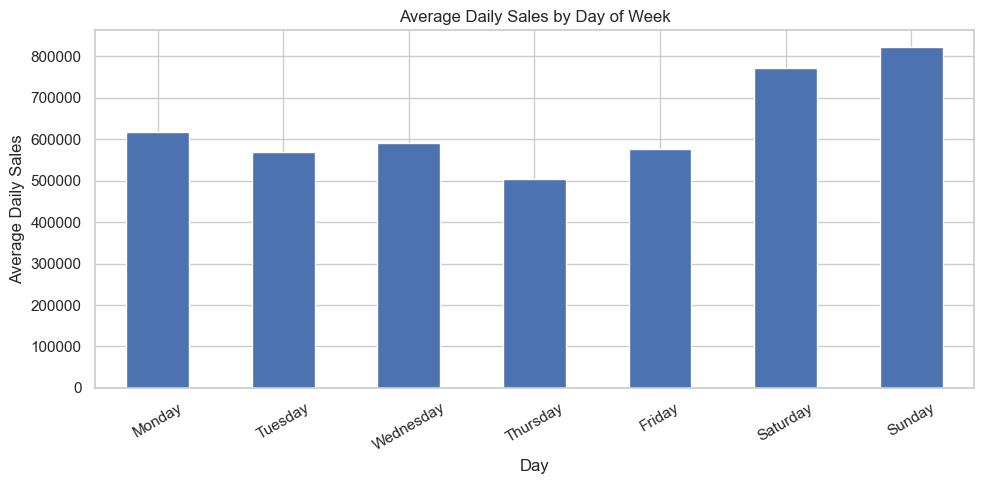

In [10]:
daily_sales["day_name"] = daily_sales["date"].dt.day_name()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekly_pattern = (
    daily_sales.groupby("day_name")["sales"]
               .mean()
               .reindex(day_order)
)

plt.figure(figsize=(10, 5))
weekly_pattern.plot(kind="bar")
plt.title("Average Daily Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Daily Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


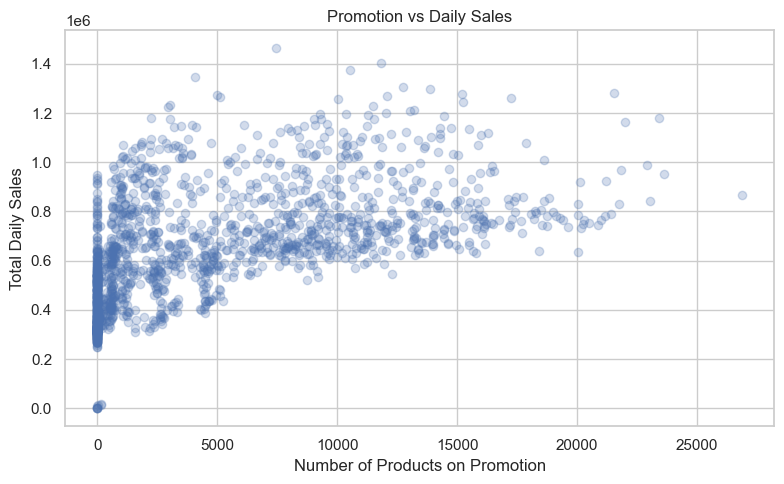

Correlation between promotion and sales: 0.5749


In [11]:
plt.figure(figsize=(8, 5))
plt.scatter(
    daily_sales["promotion"],
    daily_sales["sales"],
    alpha=0.25
)
plt.title("Promotion vs Daily Sales")
plt.xlabel("Number of Products on Promotion")
plt.ylabel("Total Daily Sales")
plt.tight_layout()
plt.show()

print("Correlation between promotion and sales:",
      daily_sales[["sales", "promotion"]].corr().loc["sales", "promotion"].round(4))


In [12]:
holiday_daily = (
    holidays.groupby("date")
            .size()
            .reset_index(name="holiday_count")
)

# Merge holiday information with the daily sales data
daily_sales = daily_sales.merge(holiday_daily, on="date", how="left")
daily_sales["holiday_count"] = daily_sales["holiday_count"].fillna(0)

print("Holiday dates in training period:",
      (daily_sales["holiday_count"] > 0).sum())

display(daily_sales[["date", "sales", "promotion", "holiday_count"]].head())


Holiday dates in training period: 256


,date,sales,promotion,holiday_count
0,2013-01-01,2511.618999,0.0,1.0
1,2013-01-02,496092.417944,0.0,0.0
2,2013-01-03,361461.231124,0.0,0.0
3,2013-01-04,354459.677093,0.0,0.0
4,2013-01-05,477350.121229,0.0,1.0


In [13]:
test_daily = (
    test.groupby("date", as_index=False)
        .agg(promotion=("onpromotion", "sum"))
        .sort_values("date")
)

test_daily = test_daily.merge(holiday_daily, on="date", how="left")
test_daily["holiday_count"] = test_daily["holiday_count"].fillna(0)

display(test_daily.head())
print("Future dates to forecast:", len(test_daily))


,date,promotion,holiday_count
0,2017-08-16,30539,0.0
1,2017-08-17,7505,0.0
2,2017-08-18,13777,0.0
3,2017-08-19,8614,0.0
4,2017-08-20,9513,0.0


Future dates to forecast: 16


## 14. Final Modeling Dataset

In [14]:
model_df = daily_sales[["date", "sales", "promotion", "holiday_count"]].copy()
model_df = model_df.set_index("date").sort_index()

y = model_df["sales"]
X = model_df[["promotion", "holiday_count"]]

print("Target observations:", len(y))
print("Target frequency:", pd.infer_freq(y.index))


Target observations: 1688
Target frequency: D


## 15. Train-Test Split for Model Evaluation

The last **30 days** of historical data are kept aside as a validation set.  
This lets us compare **actual sales vs predicted sales** before forecasting the unknown future test period.


In [15]:
VALIDATION_DAYS = 30

y_train = y.iloc[:-VALIDATION_DAYS]
y_valid = y.iloc[-VALIDATION_DAYS:]

X_train = X.iloc[:-VALIDATION_DAYS]
X_valid = X.iloc[-VALIDATION_DAYS:]

print("Training observations:", len(y_train))
print("Validation observations:", len(y_valid))
print("Validation period:", y_valid.index.min().date(), "to", y_valid.index.max().date())


Training observations: 1658
Validation observations: 30
Validation period: 2017-07-17 to 2017-08-15


In [16]:
model = SARIMAX(
    y_train,
    exog=X_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

model_fit = model.fit(disp=False)

print(model_fit.summary())


                                     SARIMAX Results                                     
Dep. Variable:                             sales   No. Observations:                 1658
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood              -21151.370
Date:                           Wed, 30 Sep 2026   AIC                          42316.739
Time:                                   11:20:05   BIC                          42354.561
Sample:                               01-01-2013   HQIC                         42330.766
                                    - 07-16-2017                                         
Covariance Type:                             opg                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
promotion        49.6992      1.289     38.565      0.000      47.173      52.225
holiday_count  1.488e+04   7418.25

## 17. Forecast the Validation Period

In [17]:
valid_forecast = model_fit.get_forecast(
    steps=len(y_valid),
    exog=X_valid
)

valid_pred = valid_forecast.predicted_mean
valid_ci = valid_forecast.conf_int()

# Prevent negative sales predictions
valid_pred = valid_pred.clip(lower=0)

mae = mean_absolute_error(y_valid, valid_pred)
rmse = np.sqrt(mean_squared_error(y_valid, valid_pred))

print(f"Validation MAE : {mae:,.2f}")
print(f"Validation RMSE: {rmse:,.2f}")


Validation MAE : 144,422.85
Validation RMSE: 175,782.05


## 18. Actual vs Forecast Sales

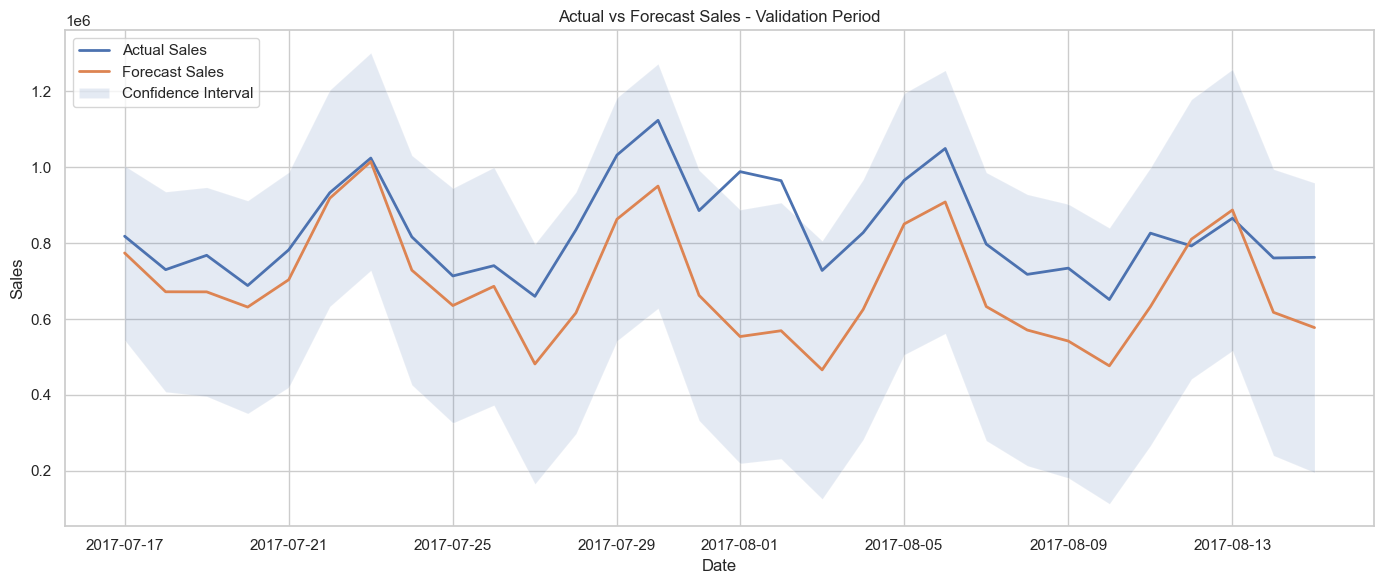

In [18]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_valid.index,
    y_valid.values,
    label="Actual Sales",
    linewidth=2
)

plt.plot(
    y_valid.index,
    valid_pred.values,
    label="Forecast Sales",
    linewidth=2
)

plt.fill_between(
    y_valid.index,
    valid_ci.iloc[:, 0].clip(lower=0),
    valid_ci.iloc[:, 1].clip(lower=0),
    alpha=0.15,
    label="Confidence Interval"
)

plt.title("Actual vs Forecast Sales - Validation Period")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()


## 19. Residual Analysis

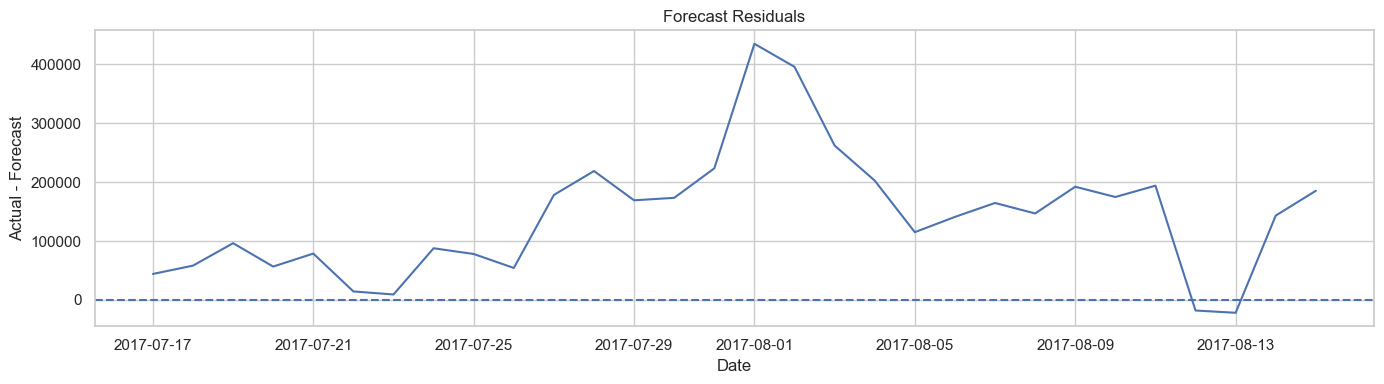

Mean residual: 141783.72


In [19]:
residuals = y_valid - valid_pred

plt.figure(figsize=(14, 4))
plt.plot(y_valid.index, residuals)
plt.axhline(0, linestyle="--")
plt.title("Forecast Residuals")
plt.xlabel("Date")
plt.ylabel("Actual - Forecast")
plt.tight_layout()
plt.show()

print("Mean residual:", residuals.mean().round(2))


In [20]:
final_model = SARIMAX(
    y,
    exog=X,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_fit = final_model.fit(disp=False)

print("Final model fitted successfully.")


Final model fitted successfully.


## 21. Forecast Future Sales

In [21]:
future_index = pd.DatetimeIndex(test_daily["date"])

X_future = (
    test_daily.set_index("date")[["promotion", "holiday_count"]]
)

future_forecast = final_fit.get_forecast(
    steps=len(future_index),
    exog=X_future
)

future_pred = future_forecast.predicted_mean.clip(lower=0)
future_ci = future_forecast.conf_int()

future_forecast_df = pd.DataFrame({
    "date": future_index,
    "forecast_sales": future_pred.values,
    "lower_ci": future_ci.iloc[:, 0].clip(lower=0).values,
    "upper_ci": future_ci.iloc[:, 1].clip(lower=0).values
})

display(future_forecast_df.head(10))


,date,forecast_sales,lower_ci,upper_ci
0,2017-08-16,1.428728e+06,1.199780e+06,1.657675e+06
1,2017-08-17,6.045955e+05,3.409025e+05,8.682884e+05
2,2017-08-18,7.628020e+05,4.872223e+05,1.038382e+06
3,2017-08-19,9.131215e+05,6.323404e+05,1.193903e+06
4,2017-08-20,9.858407e+05,7.021961e+05,1.269485e+06
5,2017-08-21,7.681119e+05,4.825345e+05,1.053689e+06
6,2017-08-22,7.193584e+05,4.322582e+05,1.006459e+06
7,2017-08-23,7.280743e+05,4.253570e+05,1.030792e+06
8,2017-08-24,6.515960e+05,3.418271e+05,9.613649e+05
9,2017-08-25,7.669877e+05,4.531994e+05,1.080776e+06


## 22. Plot Historical Sales and Future Forecast

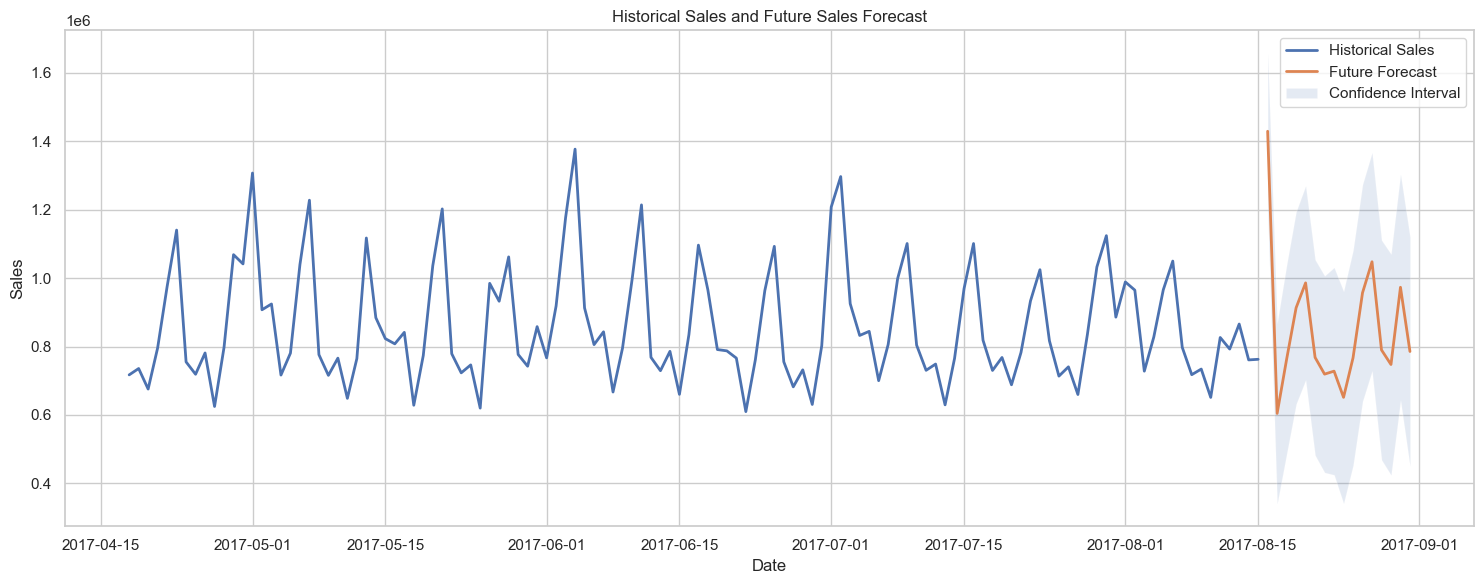

In [22]:
plt.figure(figsize=(15, 6))

recent_history = y.tail(120)

plt.plot(
    recent_history.index,
    recent_history.values,
    label="Historical Sales",
    linewidth=2
)

plt.plot(
    future_forecast_df["date"],
    future_forecast_df["forecast_sales"],
    label="Future Forecast",
    linewidth=2
)

plt.fill_between(
    future_forecast_df["date"],
    future_forecast_df["lower_ci"],
    future_forecast_df["upper_ci"],
    alpha=0.15,
    label="Confidence Interval"
)

plt.title("Historical Sales and Future Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()


In [23]:
# Allocate daily forecast to each test row using promotion share.
# If a day's total promotion is zero, use equal allocation.

test_output = test[["id", "date", "store_nbr", "family", "onpromotion"]].copy()

test_output["date"] = pd.to_datetime(test_output["date"])

daily_forecast_map = future_forecast_df.set_index("date")["forecast_sales"]

test_output["daily_forecast_total"] = test_output["date"].map(daily_forecast_map)

promotion_total_by_date = (
    test_output.groupby("date")["onpromotion"]
               .transform("sum")
)

row_count_by_date = (
    test_output.groupby("date")["id"]
               .transform("count")
)

promotion_share = np.where(
    promotion_total_by_date > 0,
    test_output["onpromotion"] / promotion_total_by_date,
    1 / row_count_by_date
)

test_output["sales"] = (
    test_output["daily_forecast_total"] * promotion_share
)

submission = test_output[["id", "sales"]].copy()
submission["sales"] = submission["sales"].clip(lower=0)

submission.to_csv(base_dir / "sales_forecast_submission.csv", index=False)

print("Saved:", base_dir / "sales_forecast_submission.csv")
display(submission.head())


Saved: C:\Users\geeta\Customer_Churn_prediction_Project\sales_forecast_submission.csv


,id,sales
0,3000888,0.000000
1,3000889,0.000000
2,3000890,93.567415
3,3000891,935.674154
4,3000892,0.000000


## 24. Forecast Summary

In [24]:
print("Forecast start:", future_forecast_df["date"].min().date())
print("Forecast end  :", future_forecast_df["date"].max().date())
print("Forecast days  :", len(future_forecast_df))

print(f"Validation MAE : {mae:,.2f}")
print(f"Validation RMSE: {rmse:,.2f}")

print("\nAverage forecast sales per day:",
      future_forecast_df["forecast_sales"].mean().round(2))

print("Total forecast sales:",
      future_forecast_df["forecast_sales"].sum().round(2))


Forecast start: 2017-08-16
Forecast end  : 2017-08-31
Forecast days  : 16
Validation MAE : 144,422.85
Validation RMSE: 175,782.05

Average forecast sales per day: 851857.63
Total forecast sales: 13629722.1
